# Experiment 10: Complete GA Optimization System using DEAP
**Aim:** To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation and convergence analysis.

**Problem:** 0/1 Knapsack – choose items maximising total value without exceeding the weight capacity.

Install DEAP if needed: `pip install deap`

In [1]:
# !pip install deap
import random
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

random.seed(42); np.random.seed(42)

## 1. Problem definition

In [2]:
N_ITEMS = 30
rng = random.Random(123)
weights = [rng.randint(1, 15) for _ in range(N_ITEMS)]
values  = [rng.randint(5, 50) for _ in range(N_ITEMS)]
CAPACITY = int(0.4 * sum(weights))
print("Number of items:", N_ITEMS, "| Capacity:", CAPACITY, "| Total weight:", sum(weights))

Number of items: 30 | Capacity: 85 | Total weight: 213


## 2. DEAP setup: fitness, individual, population initialisation

In [3]:
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=N_ITEMS)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

## 3. Fitness evaluation (with a penalty for exceeding capacity)

In [4]:
def eval_knapsack(ind):
    w = sum(g * wt for g, wt in zip(ind, weights))
    v = sum(g * vl for g, vl in zip(ind, values))
    if w > CAPACITY:
        return (max(0, v - 10 * (w - CAPACITY)),)    # penalised
    return (v,)

toolbox.register("evaluate", eval_knapsack)

## 4. Genetic operators: selection, crossover, mutation

In [5]:
toolbox.register("select", tools.selTournament, tournsize=3)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.03)

## 5. Statistics, Hall of Fame and running the GA

In [6]:
POP_SIZE, NGEN, CXPB, MUTPB = 100, 60, 0.8, 0.2

pop = toolbox.population(n=POP_SIZE)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("max", np.max)
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("std", np.std)

pop, logbook = algorithms.eaSimple(pop, toolbox, cxpb=CXPB, mutpb=MUTPB, ngen=NGEN,
                                   stats=stats, halloffame=hof, verbose=False)
for row in logbook[:3] + logbook[-3:]:
    print(f"gen {row['gen']:>3} | max {row['max']:.1f} | avg {row['avg']:.1f} | min {row['min']:.1f}")

gen   0 | max 367.0 | avg 150.2 | min 0.0
gen   1 | max 411.0 | avg 239.2 | min 0.0
gen   2 | max 440.0 | avg 292.4 | min 71.0
gen  58 | max 562.0 | avg 557.5 | min 443.0
gen  59 | max 562.0 | avg 554.2 | min 388.0
gen  60 | max 562.0 | avg 549.5 | min 402.0


## 6. Best solution

In [7]:
best = hof[0]
tw = sum(g * wt for g, wt in zip(best, weights))
tv = sum(g * vl for g, vl in zip(best, values))
print("Best chromosome :", "".join(map(str, best)))
print("Items selected  :", [i for i, g in enumerate(best) if g])
print(f"Total weight    : {tw} (capacity {CAPACITY})")
print(f"Total value     : {tv}")
print("Feasible        :", tw <= CAPACITY)

Best chromosome :

 111001100010001101110011111011
Items selected  : [0, 1, 2, 5, 6, 10, 14, 15, 17, 18, 19, 22, 23, 24, 25, 26, 28, 29]
Total weight    : 81 (capacity 85)
Total value     : 572
Feasible        : True


## 7. Verification with a dynamic-programming optimum

In [8]:
dp = [0] * (CAPACITY + 1)
for wt, vl in zip(weights, values):
    for c in range(CAPACITY, wt - 1, -1):
        dp[c] = max(dp[c], dp[c - wt] + vl)
print("Optimal value (DP):", dp[CAPACITY])
print(f"GA reached {100 * tv / dp[CAPACITY]:.1f}% of the optimum")

Optimal value (DP): 579
GA reached 98.8% of the optimum


## 8. Convergence analysis

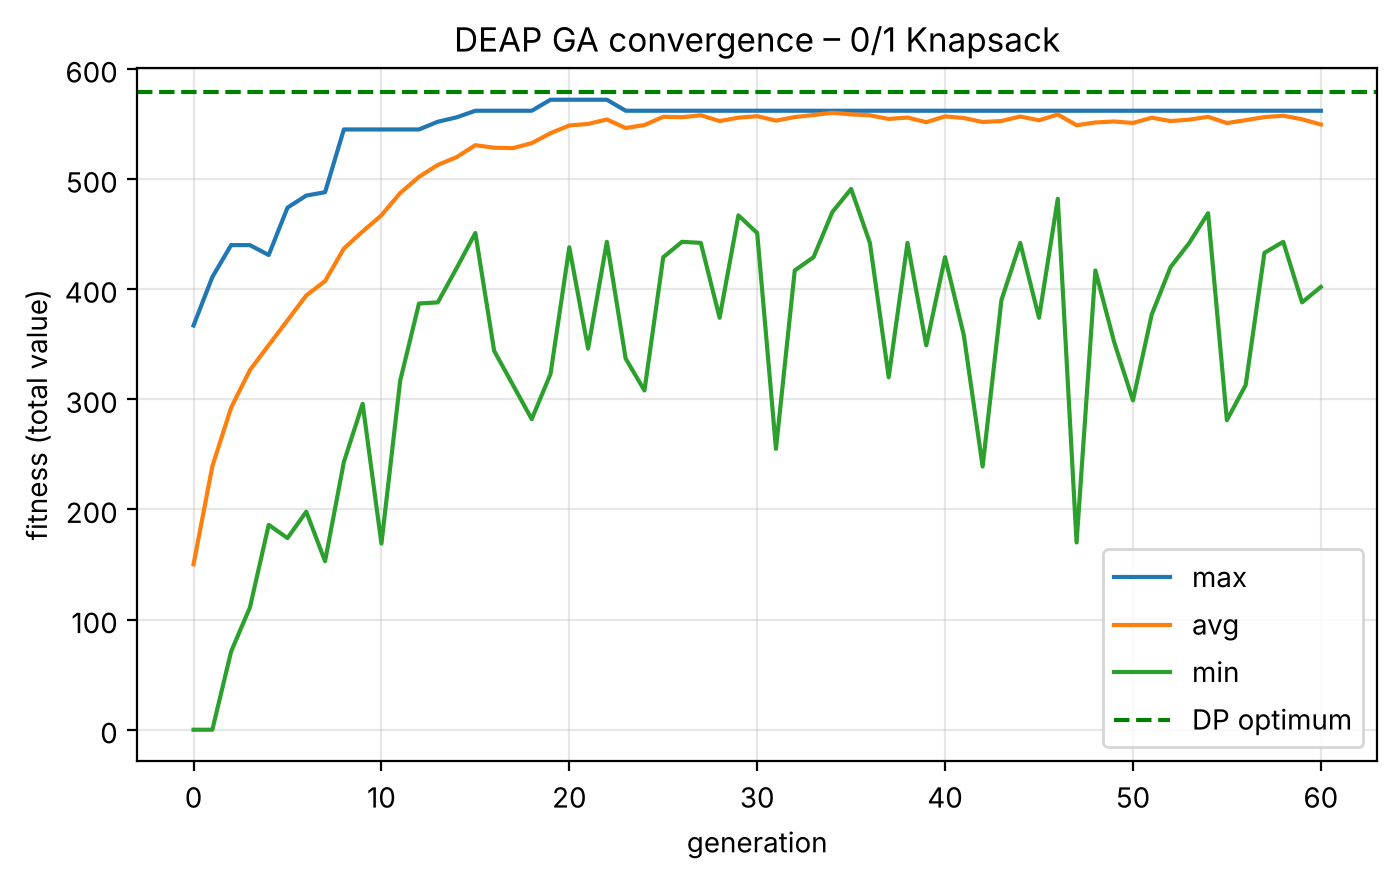

In [9]:
gen = logbook.select("gen")
mx, avg, mn = logbook.select("max"), logbook.select("avg"), logbook.select("min")
plt.figure(figsize=(8, 4.5))
plt.plot(gen, mx, label="max"); plt.plot(gen, avg, label="avg"); plt.plot(gen, mn, label="min")
plt.axhline(dp[CAPACITY], color="green", ls="--", label="DP optimum")
plt.xlabel("generation"); plt.ylabel("fitness (total value)")
plt.title("DEAP GA convergence – 0/1 Knapsack"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 9. Repeated runs for robustness

In [10]:
finals = []
for seed in range(10):
    random.seed(seed)
    p = toolbox.population(n=POP_SIZE)
    h = tools.HallOfFame(1)
    algorithms.eaSimple(p, toolbox, CXPB, MUTPB, NGEN, halloffame=h, verbose=False)
    finals.append(h[0].fitness.values[0])
print("Best fitness per run:", finals)
print(f"Mean = {np.mean(finals):.1f}, Std = {np.std(finals):.2f}, Optimum = {dp[CAPACITY]}")

Best fitness per run: [579.0, 576.0, 573.0, 570.0, 573.0, 560.0, 565.0, 579.0, 576.0, 575.0]
Mean = 572.6, Std = 5.78, Optimum = 579


## Conclusion
A complete optimisation pipeline was built with DEAP: `creator`/`toolbox` for representation and operators, tournament selection, two-point crossover, flip-bit mutation, `Statistics`/`HallOfFame` for monitoring, and `eaSimple` for the evolutionary loop. The convergence plot shows maximum and average fitness approaching the known optimum from dynamic programming.